# Score training and calibration with kNN

We use three-fold cross-validation within the training set, keeping duplicate prompts together so they never appear in both the fitting and held-out portions of a fold.
For each candidate number of neighbors $k$, we predict each LLM’s original, unprojected score by averaging its scores among the nearest training prompts, then calculate CV_MSE by averaging squared prediction errors across held-out prompts and all 11 LLMs.
We select the $k$ with the lowest CV_MSE—100 in our search, which included values up to 500—and fit the final kNN predictor using the full training set.

In [15]:
# Set up and load the training data. 

from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

PROJECT_DIR = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "1_data_preparation").is_dir()
    ),
    None,
)

if PROJECT_DIR is None:
    raise FileNotFoundError("Run this notebook from inside the project.")

DATA_DIR = (
    PROJECT_DIR
    / "1_data_preparation/data/processed/char_tfidf_50k"
)

train_questions = pd.read_pickle(DATA_DIR / "train_questions.pkl")
train_scores = pd.read_pickle(DATA_DIR / "train_scores.pkl").astype(float)

assert train_questions.index.equals(train_scores.index)
assert np.isfinite(train_scores.to_numpy()).all()
assert train_scores.ge(0).all().all()
assert train_scores.le(1).all().all()
assert train_questions["question_group"].notna().all()

print("Training prompts:", len(train_questions))
print("LLMs:", train_scores.shape[1])
print("Unique prompt groups:", train_questions["question_group"].nunique())

display(
    train_questions[
        ["sample_id", "eval_name", "question_group", "question_text"]
    ].head()
)

display(train_scores.head())

Training prompts: 21900
LLMs: 11
Unique prompt groups: 21888


,sample_id,eval_name,question_group,question_text
0,Chinese_character_riddles.dev.0,Chinese_character_riddles,0,猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)。首...
3,Chinese_character_riddles.dev.11,Chinese_character_riddles,3,猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)。首...
4,Chinese_character_riddles.dev.12,Chinese_character_riddles,4,猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)。首...
5,Chinese_character_riddles.dev.13,Chinese_character_riddles,5,猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)。首...
6,Chinese_character_riddles.dev.14,Chinese_character_riddles,6,猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)。首...


,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
# Create 3-folds for cross validation to find the right k

K_VALUES = [
    1, 2, 3, 5, 10, 20, 40, 60, 80, 100,
    150, 200, 300, 500,
]
BATCH_SIZE = 128
N_JOBS = -1

groups = train_questions["question_group"].to_numpy()

splitter = GroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

cv_splits = list(
    splitter.split(train_questions, groups=groups)
)

fold_rows = []

for fold_number, (fit_positions, heldout_positions) in enumerate(
    cv_splits,
    start=1,
):
    fit_groups = set(groups[fit_positions])
    heldout_groups = set(groups[heldout_positions])

    overlap = fit_groups.intersection(heldout_groups)

    assert len(overlap) == 0
    assert len(fit_positions) >= max(K_VALUES)

    fold_rows.append({
        "fold": fold_number,
        "fit_prompts": len(fit_positions),
        "heldout_prompts": len(heldout_positions),
        "fit_groups": len(fit_groups),
        "heldout_groups": len(heldout_groups),
        "overlapping_groups": len(overlap),
    })

display(pd.DataFrame(fold_rows).set_index("fold"))

,fit_prompts,heldout_prompts,fit_groups,heldout_groups,overlapping_groups
fold,,,,,
1,14601,7299,14592,7296,0
2,14602,7298,14592,7296,0
3,14597,7303,14592,7296,0


## Training

In [3]:
# Import kNN

import sys
import importlib
import joblib

module_dir = str(PROJECT_DIR / "2a_Score_training_calibration")

if module_dir not in sys.path:
    sys.path.insert(0, module_dir)

import score_model_knn as knn_module

importlib.invalidate_caches()
importlib.reload(knn_module)

preprocessing = joblib.load(DATA_DIR / "preprocessing.joblib")
vectorizer_template = preprocessing["tfidf_vectorizer"]

In [4]:
# cross-validation and training. 
cv_results = knn_module.cross_validate_score_knn(
    texts=train_questions["question_text"],
    scores=train_scores,
    groups=groups,
    cv_splits=cv_splits,
    vectorizer=vectorizer_template,
    k_values=K_VALUES,
    batch_size=BATCH_SIZE,
    n_jobs=N_JOBS,
)

Fold 1/3: fitting TF-IDF
Fold 1: predicting 7299 prompts
Fold 1 finished in 29.8 seconds
Fold 2/3: fitting TF-IDF
Fold 2: predicting 7298 prompts
Fold 2 finished in 29.8 seconds
Fold 3/3: fitting TF-IDF
Fold 3: predicting 7303 prompts
Fold 3 finished in 29.9 seconds


In [5]:
# display results and pick k such that it minimizes the CV_MSE.

display(cv_results["summary"].round(6))
display(cv_results["folds"].round(2))

,k,CV_MSE,baseline_CV_MSE,MSE_reduction_pct
0,100,0.157791,0.179001,11.849242
1,80,0.157799,0.179001,11.844571
2,60,0.157982,0.179001,11.742327
3,150,0.158533,0.179001,11.434561
4,40,0.158594,0.179001,11.400446
5,200,0.159527,0.179001,10.879195
6,20,0.161259,0.179001,9.911603
7,300,0.161545,0.179001,9.751658
8,500,0.163932,0.179001,8.418506
9,10,0.167859,0.179001,6.224657


,fit_prompts,heldout_prompts,features,zero_fit_rows,zero_heldout_rows,seconds
fold,,,,,,
1,14601,7299,50000,0,0,29.83
2,14602,7298,50000,0,0,29.77
3,14597,7303,50000,0,0,29.87


In [16]:
from scipy.sparse import load_npz

selected_cv_result = (
    cv_results["summary"]
    .sort_values(["CV_MSE", "k"], ascending=[True, False])
    .iloc[0]
)

best_k = int(selected_cv_result["k"])

X_train_knn = load_npz(
    DATA_DIR / "X_train.npz"
)[:, :-1].tocsr()

preprocessing = joblib.load(DATA_DIR / "preprocessing.joblib")
final_vectorizer = preprocessing["tfidf_vectorizer"]

assert train_questions.index.equals(train_scores.index)
assert X_train_knn.shape[0] == len(train_scores)
assert X_train_knn.shape[1] == len(
    final_vectorizer.get_feature_names_out()
)
assert train_scores.columns.tolist() == preprocessing["model_names"]

score_knn = knn_module.fit_score_knn(
    X_train_knn,
    train_scores,
    n_jobs=N_JOBS,
)

print("Selected k:", best_k)
print("Training features:", X_train_knn.shape)
print("Stored score targets:", score_knn["targets"].shape)

Selected k: 100
Training features: (21900, 50000)
Stored score targets: (21900, 11)


## Save training

In [ ]:
import json
import sklearn

SCORE_MODEL_DIR = PROJECT_DIR / "artifacts" / "score_knn"
SCORE_MODEL_DIR.mkdir(parents=True, exist_ok=True)

score_metadata = {
    "model_file": "model.joblib",
    "vectorizer_file": "tfidf.joblib",
    "model_names": train_scores.columns.tolist(),
    "k": best_k,
    "n_features": X_train_knn.shape[1],
    "n_training_prompts": X_train_knn.shape[0],
    "metric": "cosine",
    "algorithm": "brute",
    "weights": "uniform",
    "batch_size": BATCH_SIZE,
    "n_jobs": N_JOBS,
    "target_type": "original_observed_scores",
    "cv_k_values": sorted(K_VALUES),
    "selected_cv_mse": float(selected_cv_result["CV_MSE"]),
    "sklearn_version": sklearn.__version__,
    "calibrated": False,
}

joblib.dump(
    score_knn,
    SCORE_MODEL_DIR / score_metadata["model_file"],
    compress=3,
)

joblib.dump(
    final_vectorizer,
    SCORE_MODEL_DIR / score_metadata["vectorizer_file"],
    compress=3,
)

with (SCORE_MODEL_DIR / "metadata.json").open("w") as file:
    json.dump(score_metadata, file, indent=2)

cv_results["summary"].to_csv(
    SCORE_MODEL_DIR / "cv_summary.csv",
    index=False,
)

print("Saved:", SCORE_MODEL_DIR)

In [8]:
# Verify saving

with (SCORE_MODEL_DIR / "metadata.json").open() as file:
    saved_score_metadata = json.load(file)

loaded_score_knn = joblib.load(
    SCORE_MODEL_DIR / saved_score_metadata["model_file"]
)

check_X = X_train_knn[:5]
check_k = saved_score_metadata["k"]

before_saving = knn_module.predict_score_grid(
    score_knn,
    check_X,
    k_values=[check_k],
    batch_size=BATCH_SIZE,
)[check_k]

after_loading = knn_module.predict_score_grid(
    loaded_score_knn,
    check_X,
    k_values=[check_k],
    batch_size=BATCH_SIZE,
)[check_k]

np.testing.assert_allclose(
    before_saving,
    after_loading,
    rtol=1e-12,
    atol=1e-12,
)

print("Saved and reloaded predictions match.")

Saved and reloaded predictions match.


# Calibration diagnostics

In [18]:
# Load calibration 
calibration_questions = pd.read_pickle(
    DATA_DIR / "calibration_questions.pkl"
)

calibration_scores = pd.read_pickle(
    DATA_DIR / "calibration_scores.pkl"
).astype(float)

assert calibration_questions.index.equals(calibration_scores.index)

model_names = saved_score_metadata["model_names"]
calibration_scores = calibration_scores.loc[:, model_names]

saved_vectorizer = joblib.load(
    SCORE_MODEL_DIR / saved_score_metadata["vectorizer_file"]
)

X_calibration_knn = saved_vectorizer.transform(
    calibration_questions["question_text"]
)

assert X_calibration_knn.shape[1] == saved_score_metadata["n_features"]
assert X_calibration_knn.shape[0] == len(calibration_scores)

print("Calibration features:", X_calibration_knn.shape)
print(
    "Zero TF-IDF rows:",
    int((X_calibration_knn.getnnz(axis=1) == 0).sum()),
)

Calibration features: (3648, 50000)
Zero TF-IDF rows: 0


In [19]:
# Predict on calibration
selected_k = saved_score_metadata["k"]

calibration_prediction_array = knn_module.predict_score_grid(
    loaded_score_knn,
    X_calibration_knn,
    k_values=[selected_k],
    batch_size=saved_score_metadata["batch_size"],
)[selected_k]

knn_calibration_predictions = pd.DataFrame(
    calibration_prediction_array,
    index=calibration_questions.index,
    columns=model_names,
)

assert np.isfinite(knn_calibration_predictions.to_numpy()).all()
assert knn_calibration_predictions.ge(0).all().all()
assert knn_calibration_predictions.le(1).all().all()

display(knn_calibration_predictions.head().round(4))

,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
11,0.0575,0.06,0.0925,0.0875,0.0875,0.1725,0.05,0.04,0.085,0.065,0.1525
15,0.0575,0.06,0.0925,0.0875,0.0875,0.1725,0.05,0.04,0.085,0.065,0.1525
20,0.0575,0.06,0.0925,0.0875,0.0875,0.1725,0.05,0.04,0.085,0.065,0.1525
36,0.0575,0.06,0.0925,0.0875,0.0875,0.1725,0.05,0.04,0.085,0.065,0.1525
39,0.0575,0.06,0.0925,0.0875,0.0875,0.1725,0.05,0.04,0.085,0.065,0.1525


In [20]:
# Diagnostic table
training_mean_scores = pd.Series(
    loaded_score_knn["targets"].mean(axis=0),
    index=model_names,
)

errors = knn_calibration_predictions - calibration_scores

baseline_errors = calibration_scores.subtract(
    training_mean_scores,
    axis="columns",
)

knn_calibration_diagnostics = pd.DataFrame({
    "baseline_MSE": baseline_errors.pow(2).mean(),
    "calibration_MSE": errors.pow(2).mean(),
    "MAE": errors.abs().mean(),
    "mean_error": errors.mean(),
    "observed_mean": calibration_scores.mean(),
    "predicted_mean": knn_calibration_predictions.mean(),
})

knn_calibration_diagnostics["MSE_reduction_pct"] = 100 * (
    1
    - knn_calibration_diagnostics["calibration_MSE"]
    / knn_calibration_diagnostics["baseline_MSE"].replace(0, np.nan)
)

knn_calibration_diagnostics = knn_calibration_diagnostics[[
    "baseline_MSE",
    "calibration_MSE",
    "MSE_reduction_pct",
    "MAE",
    "mean_error",
    "observed_mean",
    "predicted_mean",
]]

knn_calibration_diagnostics.index.name = "LLM"

display(knn_calibration_diagnostics.round(4))

,baseline_MSE,calibration_MSE,MSE_reduction_pct,MAE,mean_error,observed_mean,predicted_mean
LLM,,,,,,,
WizardLM/WizardLM-13B-V1.2,0.2029,0.1904,6.1375,0.3992,0.0254,0.4237,0.4491
claude-instant-v1,0.1996,0.1843,7.6423,0.3850,0.0066,0.5989,0.6055
claude-v1,0.1902,0.1755,7.7416,0.3677,-0.0054,0.6403,0.6349
claude-v2,0.1879,0.1759,6.3584,0.3644,-0.0023,0.6454,0.6431
gpt-3.5-turbo-1106,0.1950,0.1780,8.7213,0.3736,0.0189,0.6136,0.6325
gpt-4-1106-preview,0.1256,0.1098,12.5892,0.2371,0.0034,0.7866,0.7900
meta/code-llama-instruct-34b-chat,0.1193,0.0850,28.7316,0.1839,-0.0024,0.2006,0.1982
meta/llama-2-70b-chat,0.1821,0.1230,32.4587,0.2659,-0.0079,0.3362,0.3283
mistralai/mistral-7b-chat,0.1704,0.1600,6.0934,0.3432,0.0252,0.3031,0.3283


In [21]:
knn_score_bins = {}
reliability_rows = []

for model_name in model_names:
    details = pd.DataFrame({
        "predicted": knn_calibration_predictions[model_name],
        "observed": calibration_scores[model_name],
    })

    details["bin"] = pd.qcut(
        details["predicted"],
        q=10,
        duplicates="drop",
    )

    table = (
        details.groupby("bin", observed=True)
        .agg(
            count=("observed", "size"),
            mean_prediction=("predicted", "mean"),
            mean_observed=("observed", "mean"),
        )
    )

    table["gap"] = (
        table["mean_prediction"] - table["mean_observed"]
    )

    knn_score_bins[model_name] = table

    reliability_rows.append({
        "LLM": model_name,
        "number_of_bins": len(table),
        "smallest_bin": table["count"].min(),
        "largest_bin": table["count"].max(),
        "weighted_absolute_gap": (
            table["gap"].abs() * table["count"]
        ).sum() / table["count"].sum(),
        "largest_absolute_gap": table["gap"].abs().max(),
    })

knn_reliability_summary = (
    pd.DataFrame(reliability_rows)
    .set_index("LLM")
    .sort_values("weighted_absolute_gap", ascending=False)
)

display(knn_reliability_summary.round(4))

,number_of_bins,smallest_bin,largest_bin,weighted_absolute_gap,largest_absolute_gap
LLM,,,,,
meta/llama-2-70b-chat,10,308,410,0.0413,0.1287
WizardLM/WizardLM-13B-V1.2,10,344,383,0.0390,0.0906
mistralai/mistral-7b-chat,10,298,428,0.0379,0.0998
zero-one-ai/Yi-34B-Chat,10,334,382,0.0332,0.0911
meta/code-llama-instruct-34b-chat,9,302,804,0.0323,0.0888
gpt-3.5-turbo-1106,10,319,409,0.0284,0.0502
mistralai/mixtral-8x7b-chat,10,347,390,0.0267,0.0937
claude-v1,10,321,437,0.0238,0.0443
claude-v2,10,303,458,0.0189,0.0490


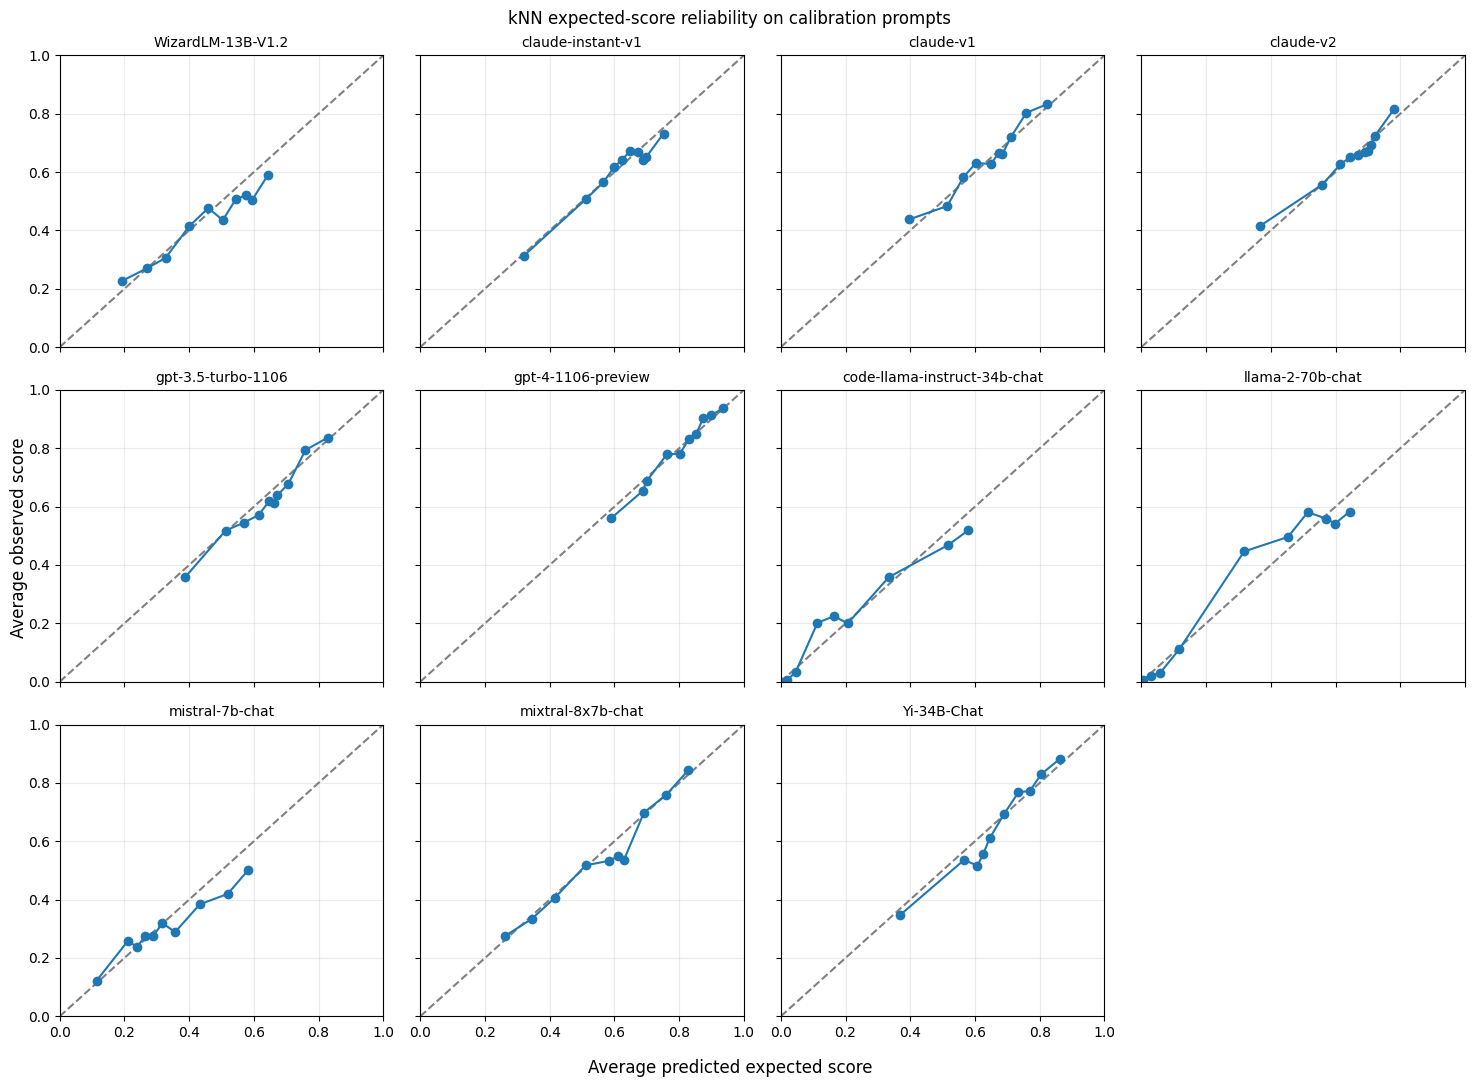

In [22]:
# reliability plots
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 4,
    figsize=(15, 11),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()

for ax, (model_name, table) in zip(axes, knn_score_bins.items()):
    ax.plot([0, 1], [0, 1], "--", color="gray")

    ax.plot(
        table["mean_prediction"],
        table["mean_observed"],
        "o-",
    )

    ax.set_title(model_name.split("/")[-1], fontsize=10)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

for ax in axes[len(knn_score_bins):]:
    ax.set_visible(False)

fig.supxlabel("Average predicted expected score")
fig.supylabel("Average observed score")
fig.suptitle("kNN expected-score reliability on calibration prompts")

plt.tight_layout()
plt.show()

## Compare with XGBoost

In [23]:
import score_model_xgb as xgb_score_module
from scipy.sparse import load_npz

importlib.reload(xgb_score_module)

xgb_score_models, xgb_score_metadata = (
    xgb_score_module.load_score_models(
        PROJECT_DIR / "artifacts" / "score_xgb"
    )
)

X_calibration_xgb = load_npz(
    DATA_DIR / "X_calibration.npz"
)[:, :-1].tocsr()

assert X_calibration_xgb.shape[0] == len(calibration_questions)

xgb_calibration_predictions = xgb_score_module.predict_scores(
    X_calibration_xgb,
    xgb_score_models,
    xgb_score_metadata,
)

xgb_calibration_predictions.index = calibration_questions.index
xgb_calibration_predictions = xgb_calibration_predictions.loc[
    :, model_names
]

xgb_errors = xgb_calibration_predictions - calibration_scores

score_comparison = pd.DataFrame({
    "knn_MSE": knn_calibration_diagnostics["calibration_MSE"],
    "xgb_MSE": xgb_errors.pow(2).mean(),
    "knn_MAE": knn_calibration_diagnostics["MAE"],
    "xgb_MAE": xgb_errors.abs().mean(),
})

score_comparison["knn_minus_xgb_MSE"] = (
    score_comparison["knn_MSE"] - score_comparison["xgb_MSE"]
)

display(
    score_comparison.sort_values("knn_minus_xgb_MSE").round(6)
)

print("Average MSE across all 11 LLMs:")
display(score_comparison[["knn_MSE", "xgb_MSE"]].mean().round(6))

,knn_MSE,xgb_MSE,knn_MAE,xgb_MAE,knn_minus_xgb_MSE
gpt-4-1106-preview,0.109752,0.110570,0.237080,0.242977,-0.000818
claude-v1,0.175486,0.176098,0.367658,0.374431,-0.000611
zero-one-ai/Yi-34B-Chat,0.159939,0.160193,0.343728,0.348536,-0.000254
mistralai/mixtral-8x7b-chat,0.178938,0.178252,0.378433,0.386635,0.000686
claude-instant-v1,0.184322,0.183345,0.385040,0.392531,0.000977
gpt-3.5-turbo-1106,0.178005,0.176014,0.373555,0.377928,0.001991
claude-v2,0.175933,0.173519,0.364355,0.370377,0.002414
mistralai/mistral-7b-chat,0.160043,0.157009,0.343245,0.339097,0.003035
WizardLM/WizardLM-13B-V1.2,0.190422,0.187337,0.399162,0.401282,0.003085
meta/code-llama-instruct-34b-chat,0.085023,0.080585,0.183859,0.184097,0.004438


Average MSE across all 11 LLMs:


knn_MSE    0.156439
xgb_MSE    0.154060
dtype: float64

## Save kNN-score calibration results

In [24]:
# Save kNN score-calibration results for sharing.
EXPORT_DIR = (
    PROJECT_DIR / "artifacts" / "score_knn" / "calibration_results"
)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

prompt_ids = calibration_questions[
    ["sample_id", "eval_name", "question_group"]
].copy()

assert prompt_ids["sample_id"].is_unique

tables = {
    "predicted_scores": knn_calibration_predictions,
    "observed_scores": calibration_scores,
}

for filename, table in tables.items():
    assert table.index.equals(prompt_ids.index)

    prompt_ids.join(
        table.loc[:, knn_calibration_predictions.columns]
    ).to_csv(
        EXPORT_DIR / f"{filename}.csv",
        index=False,
    )

# Save prediction errors and expected-score reliability summaries.
knn_calibration_diagnostics.to_csv(
    EXPORT_DIR / "diagnostics.csv",
    index_label="LLM",
)

knn_reliability_summary.to_csv(
    EXPORT_DIR / "reliability_summary.csv",
    index_label="LLM",
)

pd.concat(
    knn_score_bins,
    names=["LLM", "bin"],
).reset_index().to_csv(
    EXPORT_DIR / "reliability_bins.csv",
    index=False,
)

# Save the comparison with XGBoost and the training CV results.
score_comparison.to_csv(
    EXPORT_DIR / "knn_vs_xgb.csv",
    index_label="LLM",
)

cv_results["summary"].to_csv(
    EXPORT_DIR / "cv_summary.csv",
    index=False,
)

# Record the model configuration used for these results.
with (EXPORT_DIR / "model_metadata.json").open("w") as file:
    json.dump(saved_score_metadata, file, indent=2)

print("Saved to:", EXPORT_DIR.relative_to(PROJECT_DIR))
print("Calibration prompts:", len(prompt_ids))

Saved to: artifacts/score_knn/calibration_results
Calibration prompts: 3648
